<h1 style="font-family:verdana;color:#3399ff"><center>
PwC ML TRAINING - CLASSIFICATION </center></h1>

In [27]:
# Load all libraries
# import library pandas
import pandas as pd
# import visualisation library matplotlib
import matplotlib.pyplot as plt
# import library (LabelEncoder from sklearn) for encoding categorical columns
from sklearn.preprocessing import LabelEncoder
# import from sklearn possibility to split dataset to test and train
from sklearn.model_selection import train_test_split
# import from sklearn linear model that we want to use
from sklearn.linear_model import LogisticRegression
# import from sklearn linear model that we want to use
from sklearn.tree import DecisionTreeClassifier
# import from sklearn metrics to evaluate the model
from sklearn.metrics import r2_score , confusion_matrix , accuracy_score
from sklearn.metrics import roc_curve, roc_auc_score
# plotting library (a bit more fancy compared to matplotlib)
import seaborn as sns

%matplotlib inline

<h1 style="font-family:verdana;color:#3399ff"><center>
0. IDENTIFY YOUR TASK </center></h1>

The data is from a marketing report of a Portuguese banking institution which struggles to figure out which products their clients subscribed to. Often, more than one contact to the same client was required in order to assess if the client subscribed a certain product (bank term deposit). To reduce the total amount of phone calls needed, you'll build an ML model to automatically predict if a client has subscribed (yes/no) a term deposit (column y).

Target column:<br>
y - Has the client subscribed a term deposit? (binary: 'yes','no')

*(Data Source :https://archive.ics.uci.edu/ml/datasets/bank+marketing)*

You will train a classification model that allows us to predict which client has subscribed a term deposit - i.e., predict the 'y' column. In this example, focus on the following algos:
* Logistic Regression
* Decision Tree


Afterwards, you'll do a quick evaluation of the trained model using the following metrics:
* Accuracy
* ROC


<h1><center>1. LOAD THE DATA</center></h1>


In [28]:
# Load dataset
df = pd.read_csv('data.csv', sep=';')

In [29]:
# Look into the first 10 rows of a data frame
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


<h1><center>2. GET FAMILIAR WITH THE LOADED DATA</center></h1>

In [30]:
# TODO Exercise :  Look into the shape of data frame
df.shape

(4521, 17)

In [31]:
# TODO Exercise : Look into the informations about your datarame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 600.6 KB


<h3><center>Categorical columns: Bar plots</center></h3>

To get a better feeling for the data and it's distribution, it is highly recommended to generate some visual interpretations - for categorical columns, a bar plot would be a good idea.

<Axes: xlabel='marital'>

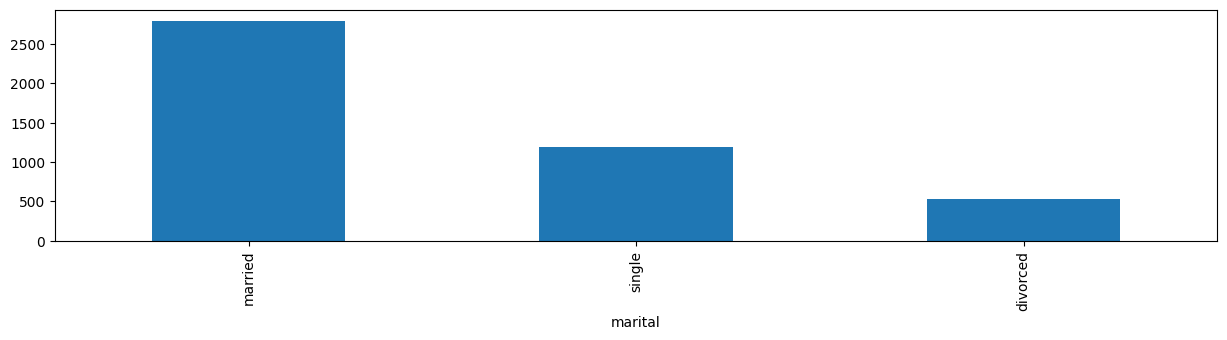

In [32]:
# Draw bar plot for column 'marital'
df['marital'].value_counts().plot(kind='bar',  figsize=(15,3))

<Axes: xlabel='job'>

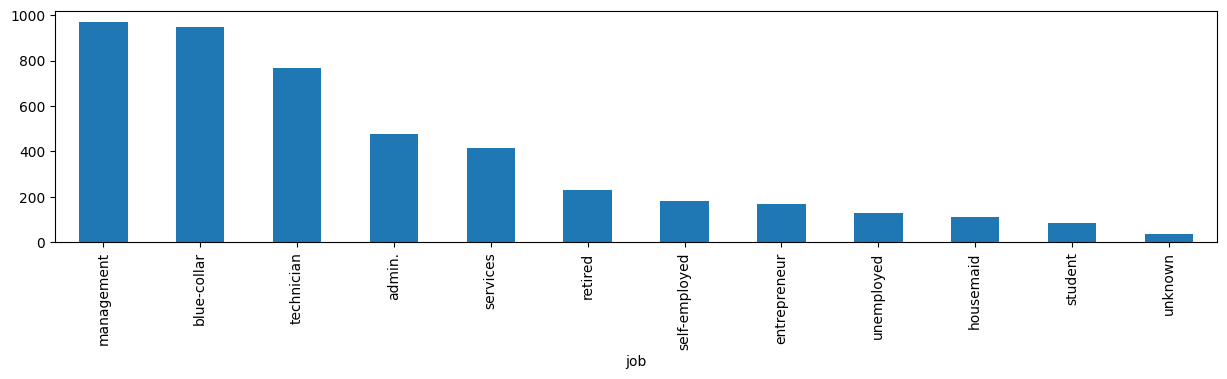

In [33]:
# TODO Exercise : Create a bar plot for variable 'job'
df['job'].value_counts().plot(kind='bar',  figsize=(15,3))

<h3><center>Numerical columns: Histograms</center></h3>

Now, using visual aids to understand the data is useful for numerical columns as well - however, using bar plots might not be the best approach. Instead, there's a variety of plots we could use, for example, histograms:

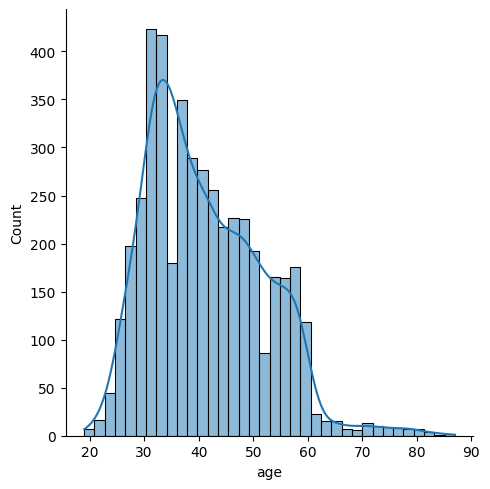

In [34]:
# Draw histogram for column 'age'
sns.displot(df['age'], kde=True)

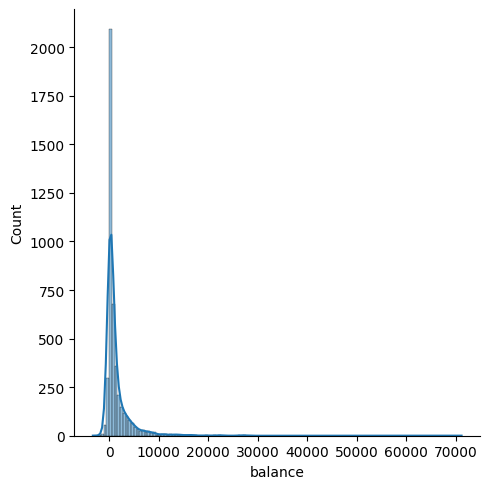

In [35]:
#TODO Exercise : Create histogram plot for column 'balance'
sns.displot(df['balance'], kde=True)

<h1><center>3. SELECT AND PREPROCESS COLUMNS</center></h1>

After we have developed a solid understanding of the data, it's time to decide which columns ('features') need processing or even removal. In ML terms, this is called *Feature Selection* or *Feature Engineering*.

In reality, there would me many many more steps taken up until here to better understand the data: Correlation checks, Normalization, Outlier detection, ... - to keep the training short, we already performed some analyses and came to the conclusion of dropping some columns completely (since they don't provide any value in the prediction), while transforming the data types of a few other:

In [36]:
# Drop columns 'poutcome' and 'duration'
df = df.drop(columns=['poutcome','duration'])

In [37]:
# TODO Exercise : Remove columns 'contact', 'day', 'pdays'
df = df.drop(columns=['contact', 'day', 'pdays'])

In [38]:
# Tip: Remember that you can check the columns with
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   month      4521 non-null   str  
 9   campaign   4521 non-null   int64
 10  previous   4521 non-null   int64
 11  y          4521 non-null   str  
dtypes: int64(4), str(8)
memory usage: 424.0 KB


To make sure the algorithms can process them, we need to change our binary ("yes" or "no") columns into numeric values:

In [41]:
# Lists columns with yes/no 
binary_cols = ['default', 'housing']

# Change columns 'default' and 'housing' to numeric values
for col in binary_cols:
    if col in df.columns:
        df[col] = df[col].map({'yes': 1, 'no': 0})

In [42]:
# TODO Excercise: Change columns 'loan' and 'y' to numeric values
binary_cols2 = ['loan', 'y']

for col in binary_cols2:
    if col in df.columns:
        df[col] = df[col].map({'yes': 1, 'no': 0})

In [43]:
df.head(5)

,age,job,marital,education,default,balance,housing,loan,month,campaign,previous,y
0,30,unemployed,married,primary,0,1787,0,0,oct,1,0,0
1,33,services,married,secondary,0,4789,1,1,may,1,4,0
2,35,management,single,tertiary,0,1350,1,0,apr,1,1,0
3,30,management,married,tertiary,0,1476,1,1,jun,4,0,0
4,59,blue-collar,married,secondary,0,0,1,0,may,1,0,0


We need to convert non-binary columns such as Job or Marital Status to numeric values as well.

Now, we could do the same as with binary columns and e.g. assign each marital status a different number -- but think about this a moment from a computer's perspective: When Married is replaced with 0, Single with 1 and Divorced with 2, that would imply a numeric relation between Single and Married.

In other terms, Divorced would be 2x Single - which not only sounds strange, but leads to very weird results as well.

So instead, we follow an approach called **One-Hot Encoding**: Each marital status get a new column, e.g. marital_single, marital_married and marital_divorced, where 0 or 1 indicates the status:

In [44]:
# Encode the more complex categorical columns
df = pd.get_dummies(data=df, columns = ['job', 'marital', 'education' , 'month'], \
                                   prefix = ['job', 'marital', 'education' , 'month'])
df.head()

,age,default,balance,housing,loan,campaign,previous,y,job_admin.,job_blue-collar,...,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep
0,30,0,1787,0,0,1,0,0,False,False,...,False,False,False,False,False,False,False,False,True,False
1,33,0,4789,1,1,1,4,0,False,False,...,False,False,False,False,False,False,True,False,False,False
2,35,0,1350,1,0,1,1,0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,30,0,1476,1,1,4,0,0,False,False,...,False,False,False,False,True,False,False,False,False,False
4,59,0,0,1,0,1,0,0,False,True,...,False,False,False,False,False,False,True,False,False,False


<h1><center>4. TRAIN & EVALUATE YOUR MODEL(S)</center></h1>

In [45]:
# To proceed the training, datasets needs to be splited to train and testing samples.
X = df.drop(columns=['y'])
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

<h3><center>Descision Tree</center></h3>

In [46]:
# Train a decision tree model
dectree = DecisionTreeClassifier()
dectree.fit(X_train, y_train)
y_pred = dectree.predict(X_test)

In [47]:
# Accuracy score
acc = dectree.score(X_test, y_test)
print(f'Accuracy score: {acc*100}%')

Accuracy score: 80.54818744473917%


<h3><center>Logistic Regression</center></h3>

In [48]:
# TODO Excercise: Train a logistic regression model
# Tip: Look at the imports at the top of this notebook to get the correct name of the algo!
logreg = LogisticRegression()
logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)
# Bonus excercise: When running your code, a warning will appear. Do you have an idea how to fix it?

/workspaces/HandOnML1/tutorial_env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [49]:
# Accuracy score
acc = logreg.score(X_test, y_test)
print(f'Accuracy score: {acc*100}%')

Accuracy score: 87.70999115826702%


Confusion Matrix 
 [[992   1]
 [138   0]]


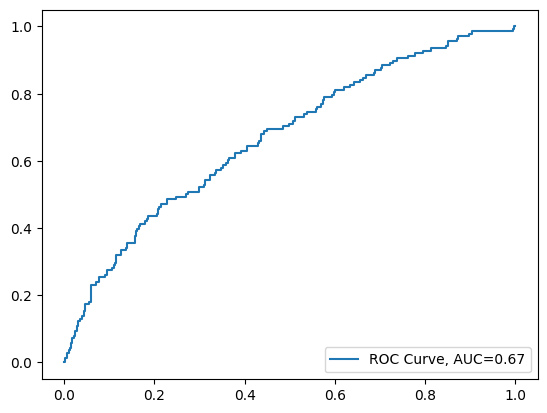

In [50]:
# Run this code to evaluate your model
print("Confusion Matrix \n", confusion_matrix(y_test, y_pred))

# AUC score
y_pred_proba = logreg.predict_proba(X_test)
auc = roc_auc_score(y_test, y_pred_proba[:,1])

# ROC curve
fpr, tpr, _ = roc_curve(y_test,  y_pred_proba[:,1])
plt.plot(fpr,tpr,label=f"ROC Curve, AUC={auc:.2f}")
plt.legend(loc=4)
plt.show()